In [39]:
import sys

sys.path.append("../src")
from configs.load_config import load_config
from data_processing.load import load_dataset
from models.build import build_model
from training.train import train_torch, sample_numpyro
import matplotlib.pyplot as plt
from training.evaluate import evaluate_model, evaluate_numpyro
from training.plot import (
    plot_qr_hdi_prediction,
    plot_quantile_calibration,
    plot_residuals,
    plot_qr_hdi_prediction,
    plot_quantile_calibration,
    plot_first_layer_feature_posteriors,
    plot_bnn_weight_posteriors,
    plot_posterior_predictive_vs_likelihood,
    plot_stacked_hdi_intervals,
    plot_pit_histogram,
    extract_quantile_curves,
    evaluate_and_plot_qr_ensemble_medians,
    plot_posterior_predictive_family,
)
import torch
import numpy as np
import numpyro
from data_processing.utils import (
    load_torch_model,
    load_checkpoint,
    save_scaler_params,
    approximate_qr_intervals,
)
import pandas as pd

In [24]:
# model_cfg = load_config("../configs/model/torch_model_quantile.yaml")
# file_name = "WindPowerQuantile_2025-12-21_10-21-23_forecast_gen_ELSPOT_NO1"

model_cfg = load_config("../configs/model/bnn_gen_model_forecast.yaml")
data_cfg = load_config(model_cfg.data.path)
file_name = "model_mw_gamma_2025-12-20_19-24-33_forecast_ELSPOT_NO1"

# model_cfg = load_config("../configs/model/bnn_gen_model_nowcast.yaml")
# file_name = "model_mw_gamma_2025-12-20_20-08-12_nowcast_ELSPOT_NO1"

In [ ]:
data = load_dataset(data_cfg)

Loading forecast data for ELSPOT NO1, ensemble members [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]...
RangeIndex(start=0, stop=6874212, step=1)
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=6874212, step=1)
Before 2-day ahead filtering: 438126 rows
After 2-day ahead filtering: 164124 rows
Lead time range: 34.0h to 61.0h


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:381: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast_filtered["hour"] = weather_forecast_filtered["time"].dt.hour


['windpark', 'wind_speed_10m_member_0', 'wind_speed_10m_member_1', 'wind_speed_10m_member_2', 'wind_speed_10m_member_3', 'wind_speed_10m_member_4', 'wind_speed_10m_member_5', 'wind_speed_10m_member_6', 'wind_speed_10m_member_7', 'wind_speed_10m_member_8', 'wind_speed_10m_member_9', 'wind_speed_10m_member_10', 'wind_speed_10m_member_11', 'wind_speed_10m_member_12', 'wind_speed_10m_member_13', 'wind_speed_10m_member_14', 'windpark_id', 'wind_direction_10m_x_member_0', 'wind_direction_10m_x_member_1', 'wind_direction_10m_x_member_2', 'wind_direction_10m_x_member_3', 'wind_direction_10m_x_member_4', 'wind_direction_10m_x_member_5', 'wind_direction_10m_x_member_6', 'wind_direction_10m_x_member_7', 'wind_direction_10m_x_member_8', 'wind_direction_10m_x_member_9', 'wind_direction_10m_x_member_10', 'wind_direction_10m_x_member_11', 'wind_direction_10m_x_member_12', 'wind_direction_10m_x_member_13', 'wind_direction_10m_x_member_14', 'wind_direction_10m_y_member_0', 'wind_direction_10m_y_member_

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Preprocessing done. X_train shape: (18141, 6, 15, 11)
Preprocessing done. X_test shape: (1881, 6, 15, 11)


In [4]:
save_scaler_params(
    scaler_params=data["scaler_params"],
    site_scaler_params=data["site_scaler_params"],
    bid_zone=model_cfg.data.bid_zone,
    split_time=pd.Timestamp("2025-01-01 00:00:00", tz="CET"),
    dataset=data_cfg.dataset,
    dir_path="../checkpoints",
)

Saved scaler parameters for ELSPOT NO1: ../checkpoints/scaler_params_ELSPOT_NO1_forecast.pkl


'../checkpoints/scaler_params_ELSPOT_NO1_forecast.pkl'

In [26]:
if model_cfg.backend == "torch":
    # Quantiles
    if model_cfg.params.quantiles is None:
        quantiles = torch.linspace(0, 1, 51)
    else:
        quantiles = torch.tensor(model_cfg.params.quantiles)

    model, checkpoint = load_torch_model(
        file_name=file_name,
    )

    metrics, y_pred = evaluate_model(
        model=model,
        data=data,
        quantiles=quantiles,
        model_cfg=checkpoint["model_cfg"],
        data_cfg=data_cfg,
    )

    hdis, _, _, _ = approximate_qr_intervals(
        Y_pred=y_pred,
        taus=quantiles,
        cred_mass=0.95,
    )

    # Extract curves, TODO: not 95% CI!!
    median, lower, upper = extract_quantile_curves(
        Y_pred_quantiles=y_pred,
        quantiles=quantiles,
        median_q=0.5,
        lower_q=0.02,
        upper_q=0.98,
    )

    percentiles = np.stack([lower, upper], axis=1)

elif model_cfg.backend == "numpyro":

    checkpoint = load_checkpoint(file_name=file_name)
    model = build_model(model_cfg, data)

    metrics, y_pred, predictive, median, percentiles, hdis = evaluate_numpyro(
        model, checkpoint["samples"], checkpoint["rng_key_predict"], data, model_cfg
    )


print(metrics)
# assert checkpoint["model_cfg"] == model_cfg

Loading specified checkpoint: ../checkpoints/model_mw_gamma_2025-12-20_19-24-33_forecast_ELSPOT_NO1.pkl
{'rmse_median': np.float32(152.5368), 'coverage_025_975': np.float64(0.8825093035619351), 'coverage_0_50': np.float64(0.07230196703880915)}


### Plots


In [30]:
if model_cfg.backend == "numpyro":
    X_test = data["X_test"]
    if len(X_test.shape) == 4:
        X_test = X_test[:, :, 0]
    graph = numpyro.render_model(
        model,
        model_args=(X_test,),
    )
    graph

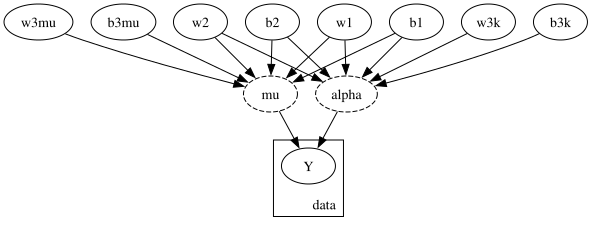

In [31]:
graph

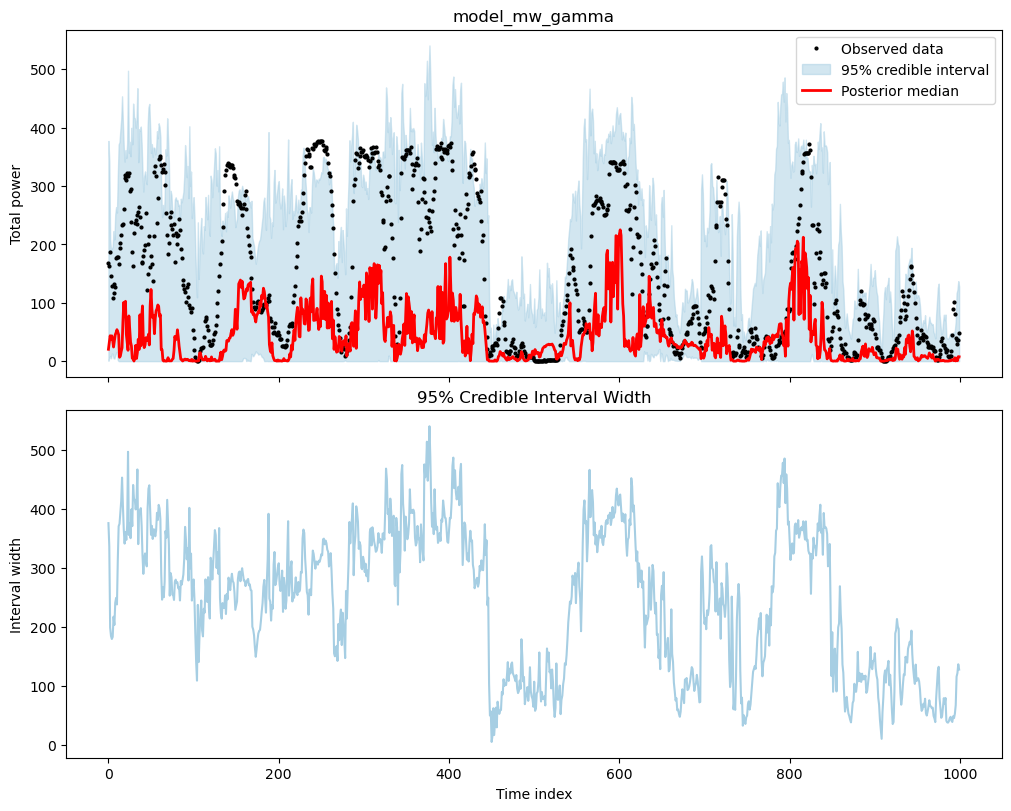

In [32]:
# Plot

fig, axes = plot_qr_hdi_prediction(
    Y_true=data["Y_test_gen"],
    conf_interval=percentiles,
    medians=median,
    n_plot=1000,
    title=model_cfg.name,
)
plt.show()

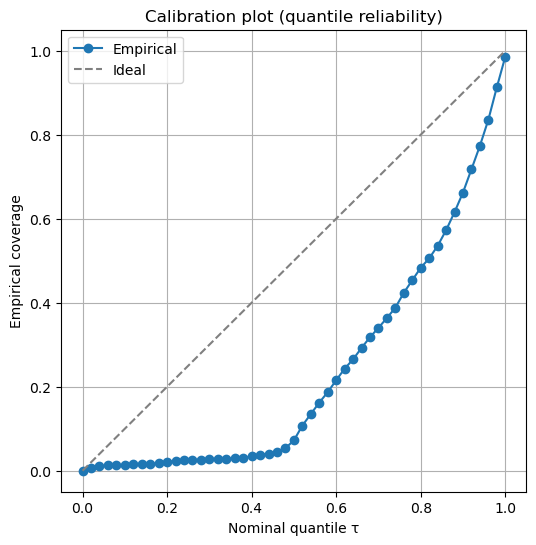

In [33]:
# y_pred: (S, N)

quantiles = torch.linspace(0, 1, 51)
emp_cov = plot_quantile_calibration(
    Y_pred_quantiles=(
        np.quantile(y_pred, quantiles, axis=0).T
        if model_cfg.backend == "numpyro"
        else y_pred
    ),
    Y_true=(
        data["Y_test_gen"] if model_cfg.params.target == "gen" else data["Y_test_cf"]
    ),
    quantiles=quantiles,
)

skew: 0.39466217


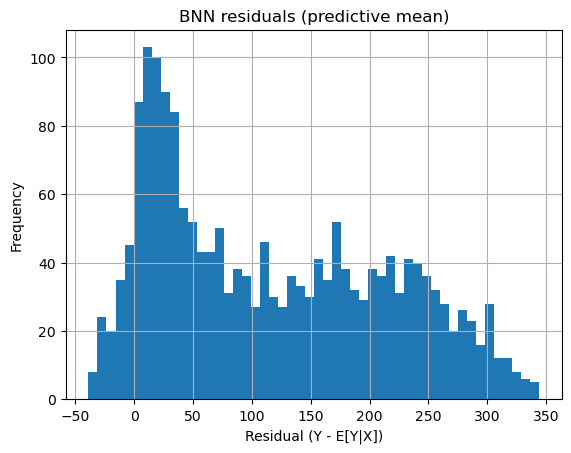

array([148.38727, 131.25119, 144.19609, ..., 303.72958, 292.97577,
       277.2712 ], shape=(1881,), dtype=float32)

In [34]:
plot_residuals(
    median,
    data["Y_test_gen"],
)

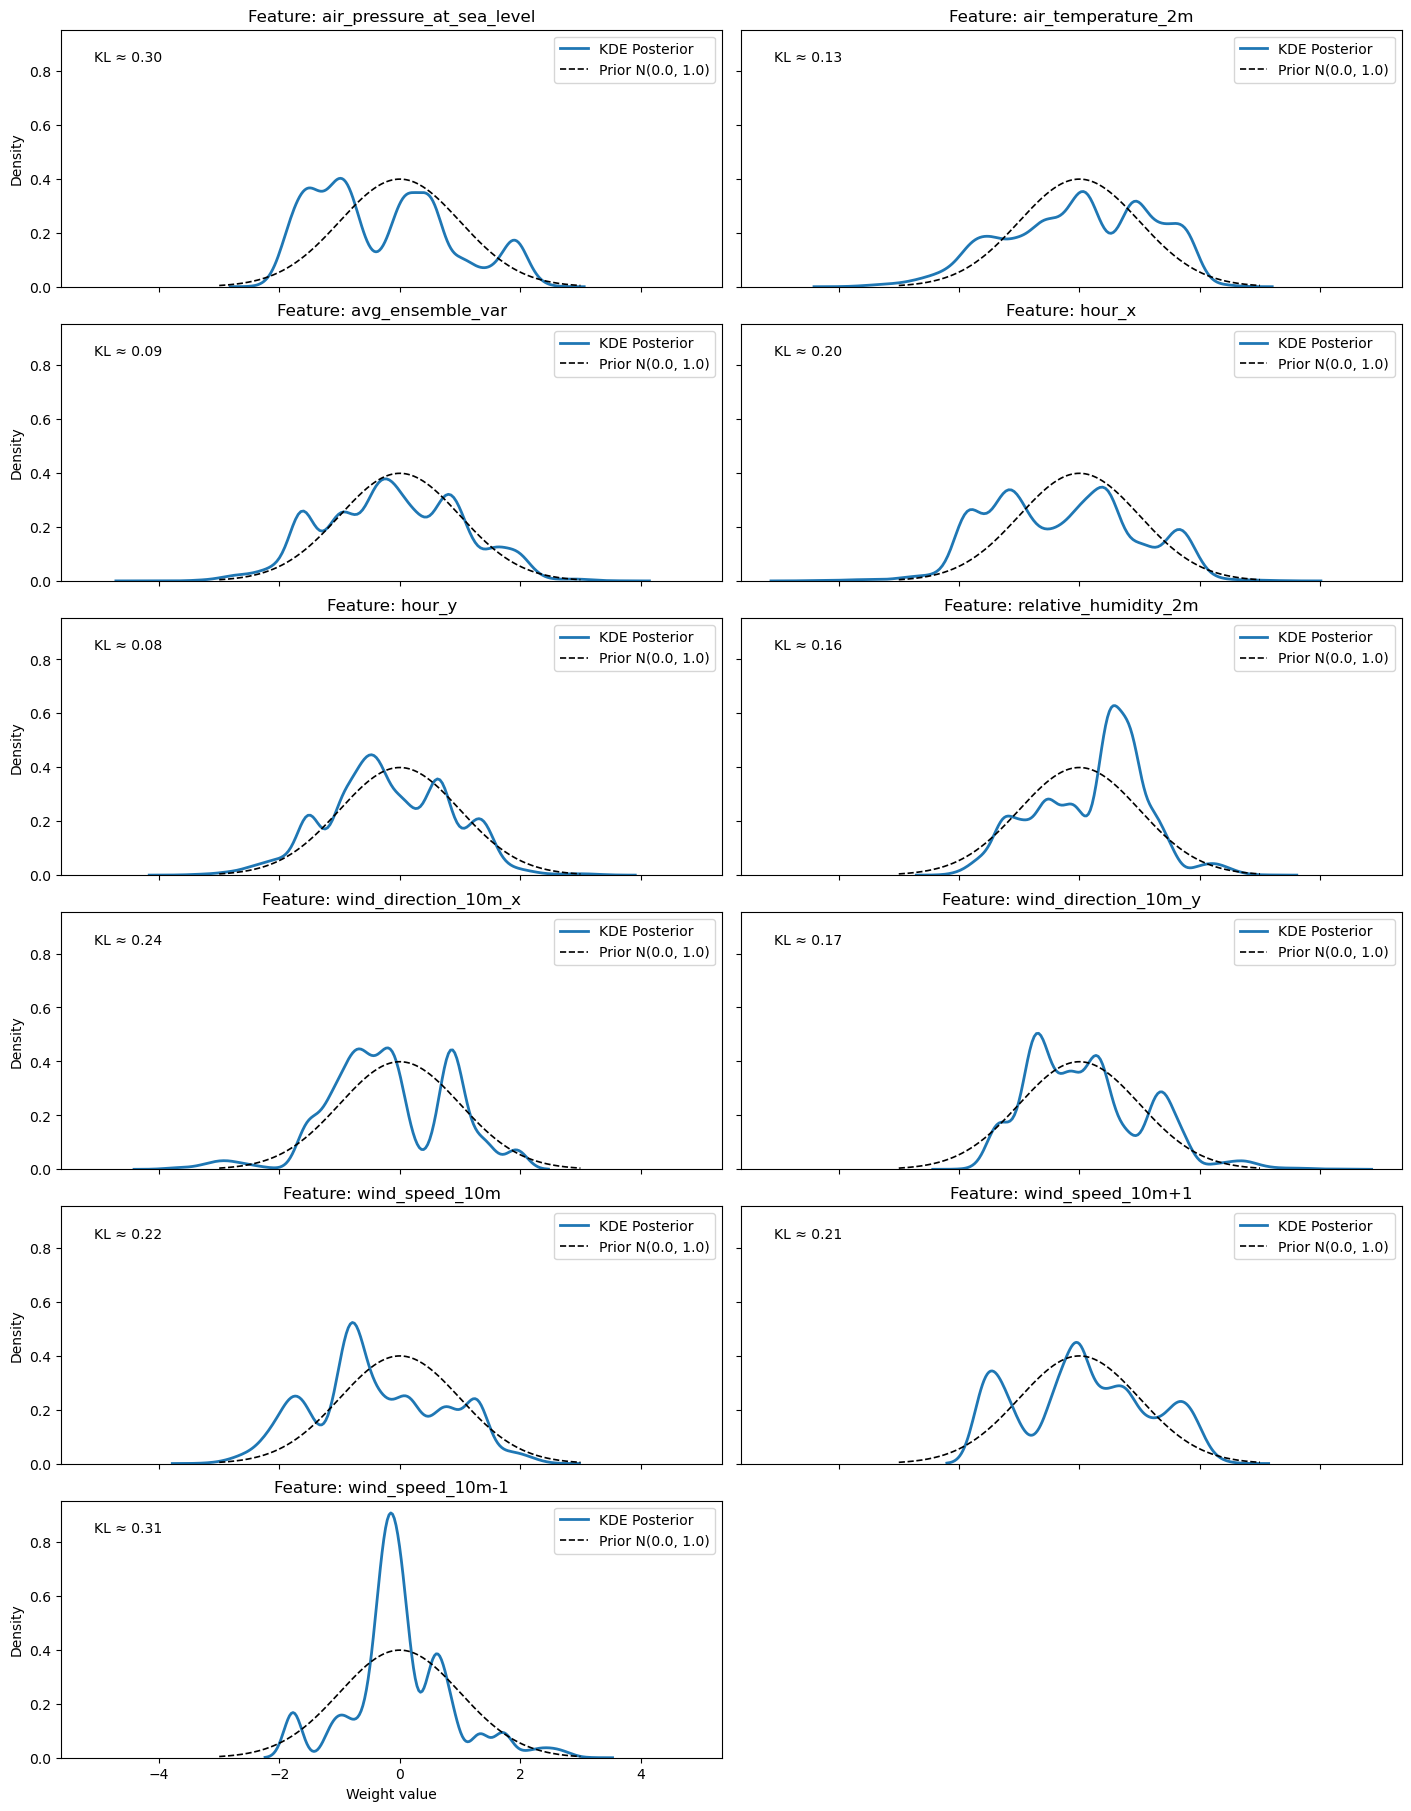

In [35]:
if model_cfg.backend == "numpyro":
    plot_first_layer_feature_posteriors(checkpoint["samples"], data)

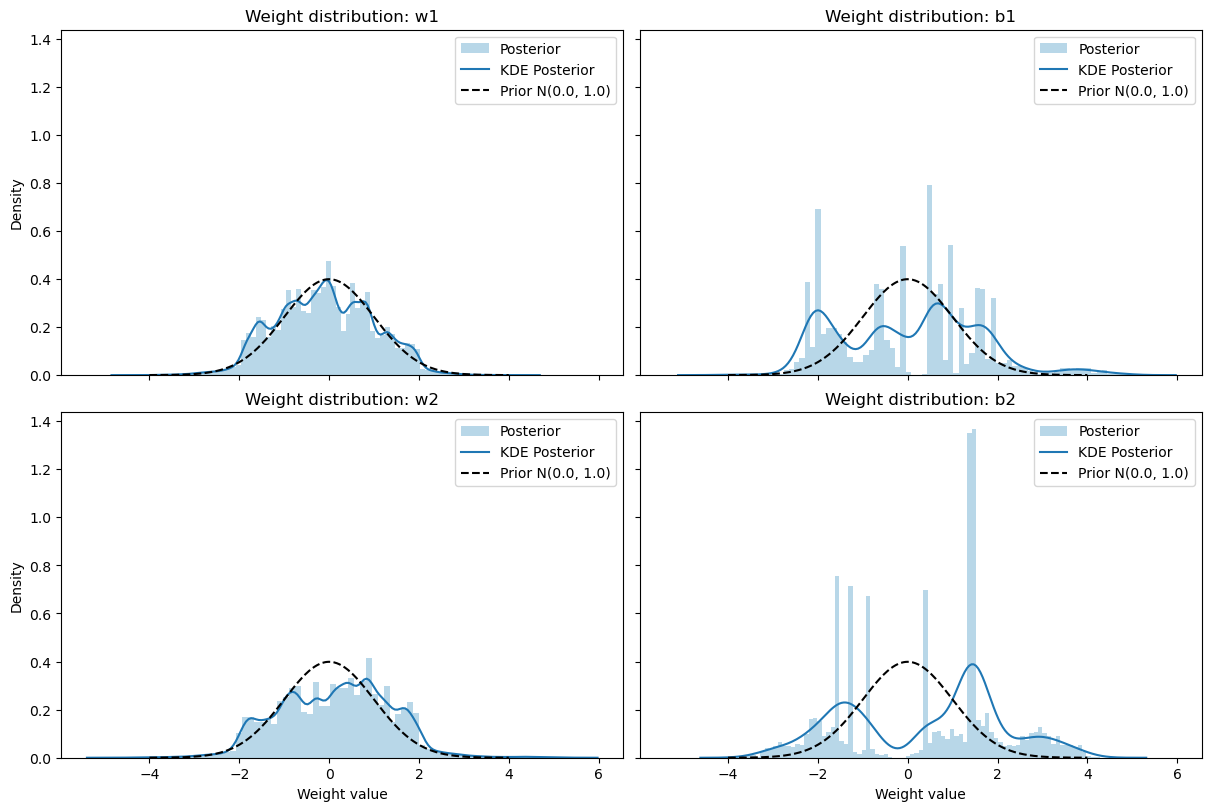

In [36]:
if model_cfg.backend == "numpyro":
    plot_bnn_weight_posteriors(checkpoint["samples"])

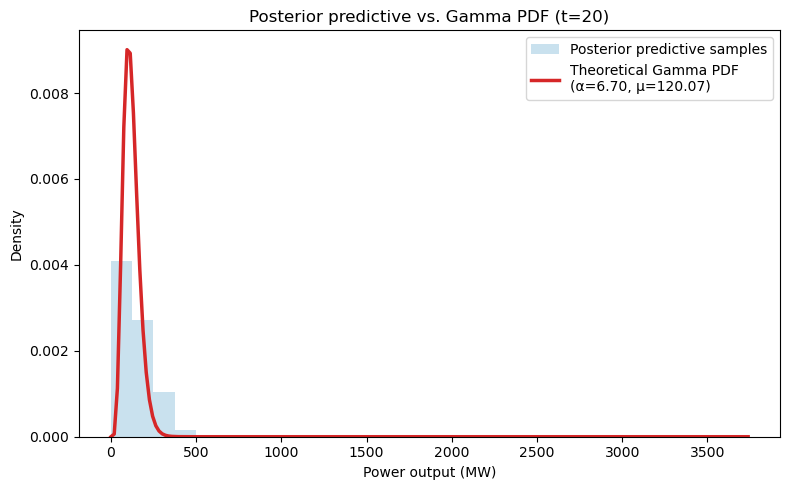

In [37]:
if model_cfg.backend == "numpyro":
    plot_posterior_predictive_vs_likelihood(
        predictive=predictive,
        model_name=model_cfg.name,
        t=20,
    )

Y not none
319.0532531738281


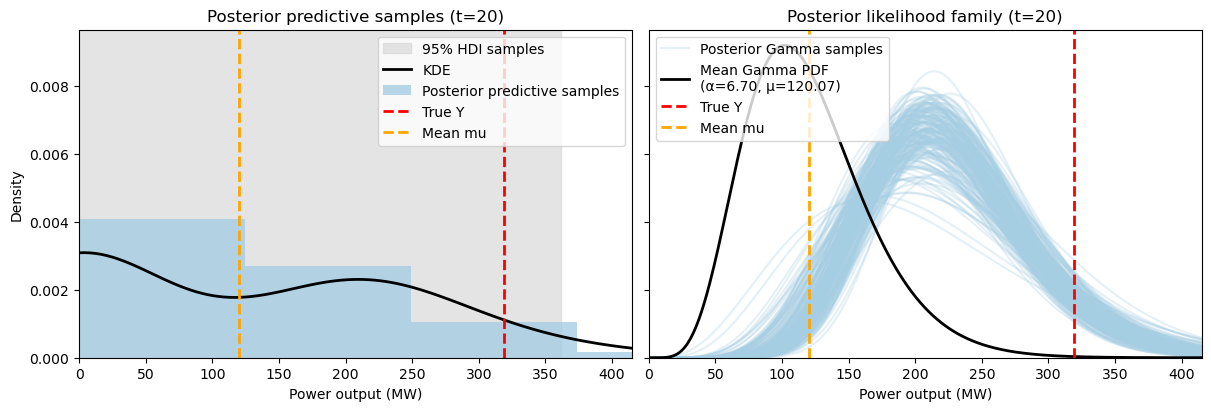

In [40]:
if model_cfg.backend == "numpyro":
    plot_posterior_predictive_family(predictive, model_cfg, data, t=20, hdi=percentiles)

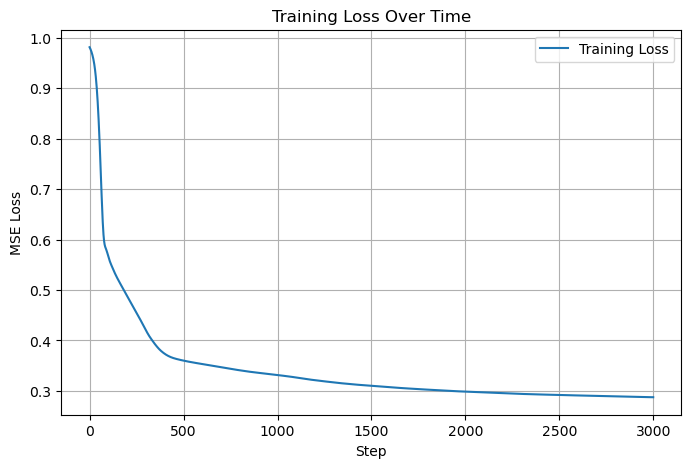

In [ ]:
if model_cfg.backend == "torch":
    plt.figure(figsize=(8, 5))
    plt.plot(checkpoint["losses"], label="Training Loss")
    plt.xlabel("Step")
    plt.ylabel("MSE Loss")
    plt.title("Training Loss Over Time")
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
if model_cfg.backend == "numpyro":
    plot_stacked_hdi_intervals(
        preds=y_pred,
        Y_true=data["Y_test_gen"],
        n_plot=1000,
    )

In [ ]:
if model_cfg.backend == "numpyro":
    pits = plot_pit_histogram(
        preds=y_pred,
        Y_true=data["Y_test_gen"],
    )

Member 0 RMSE: 72.2500
Member 1 RMSE: 82.7226
Member 2 RMSE: 81.4397
Member 3 RMSE: 82.7786
Member 4 RMSE: 78.8453
Member 5 RMSE: 80.5943
Member 6 RMSE: 79.0837
Member 7 RMSE: 75.1047
Member 8 RMSE: 77.4981
Member 9 RMSE: 78.0777
Member 10 RMSE: 76.2902
Member 11 RMSE: 79.3508
Member 12 RMSE: 77.8663
Member 13 RMSE: 81.4467
Member 14 RMSE: 84.3031

Average RMSE: 79.1768


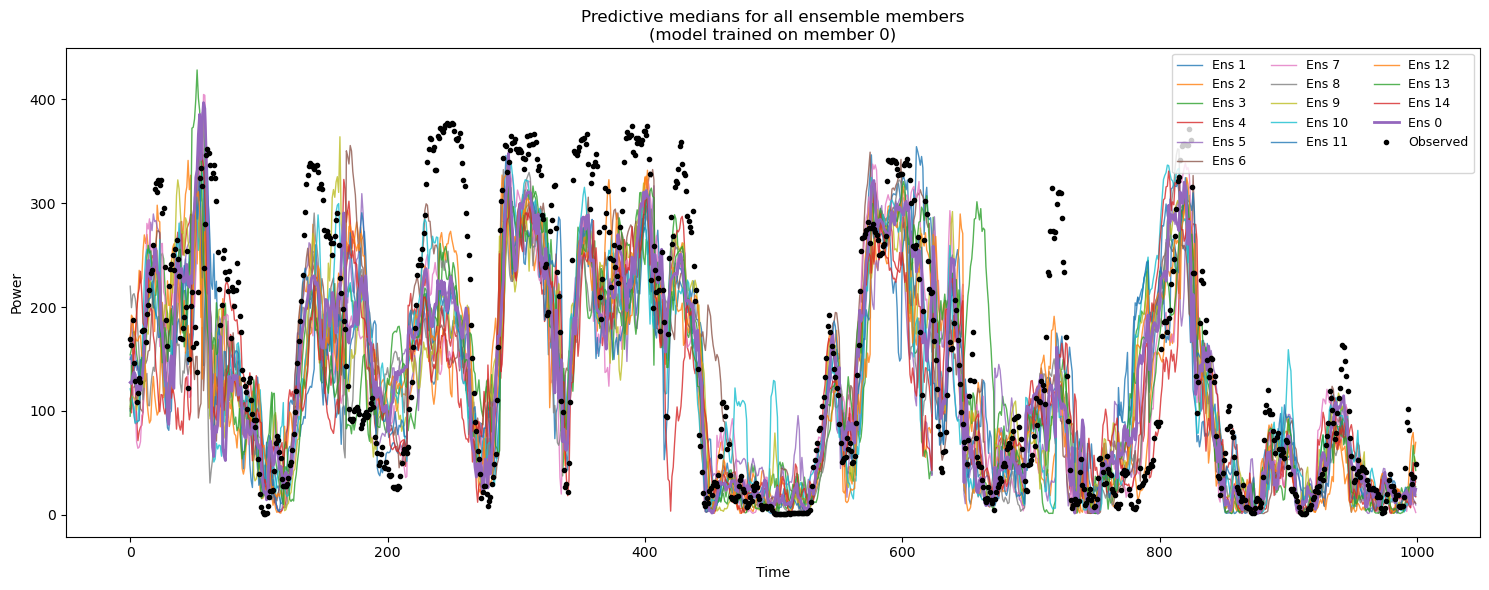

In [ ]:
if model_cfg.backend == "torch":
    evaluate_and_plot_qr_ensemble_medians(
        model=model,
        data=data,
        quantiles=quantiles,
        n_members=15,
        n_plot=1000,
    )